In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, auc, classification_report, confusion_matrix

# 1. Загрузка данных
df = pd.read_csv('../data/sales.csv')

# 2. Предобработка
# Целевая переменная: Member = 1, Normal = 0
y = (df['Customer type'] == 'Member').astype(int)

# Для простоты возьмем несколько категориальных и числовых признаков
X = df[['Branch', 'City', 'Gender', 'Unit price', 'Sales']]
X = pd.get_dummies(X, drop_first=True) # Быстрое One-Hot кодирование

# 3. Разделение
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Обучение модели
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# 5. Получение ВЕРОЯТНОСТЕЙ (predict_proba) для положительного класса (Member)
y_probs = model.predict_proba(X_test)[:, 1]

print("Модель обучена. Выведены вероятности для первых 5 клиентов из теста:")
print(y_probs[:5])

Модель обучена. Выведены вероятности для первых 5 клиентов из теста:
[0.64891723 0.51186158 0.50857702 0.60778619 0.46943967]


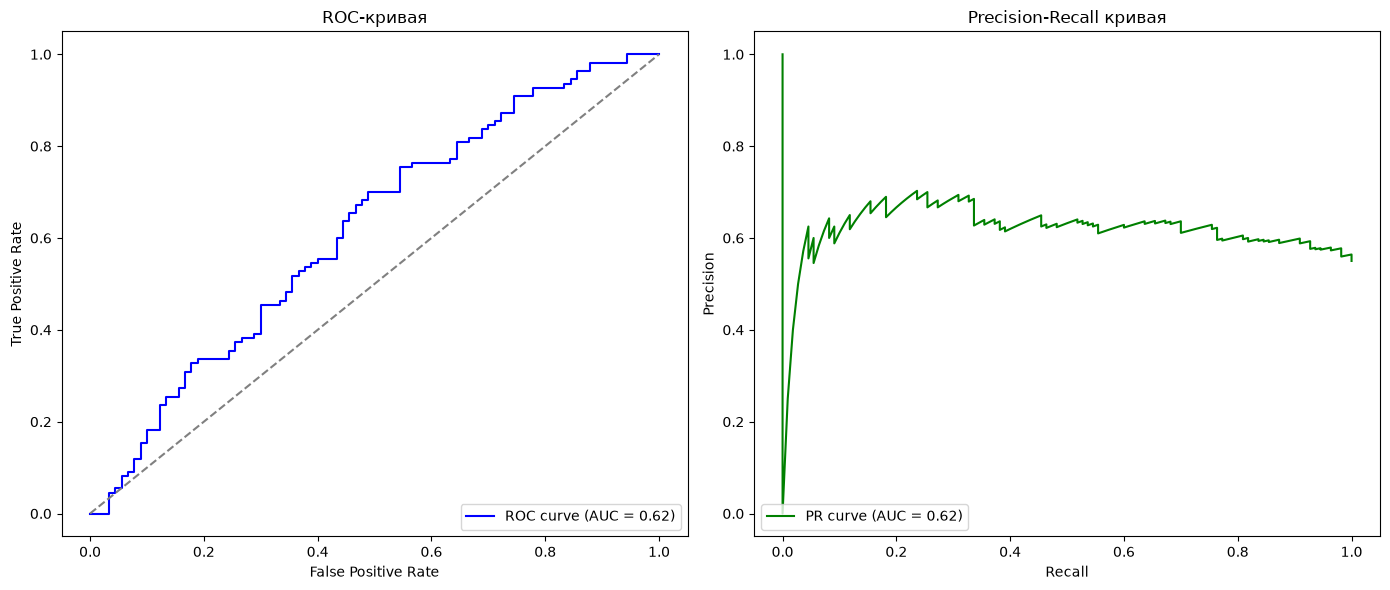

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- ROC-кривая ---
fpr, tpr, thresholds_roc = roc_curve(y_test, y_probs)
roc_auc = roc_auc_score(y_test, y_probs)

axes[0].plot(fpr, tpr, color='blue', label=f'ROC curve (AUC = {roc_auc:.2f})')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC-кривая')
axes[0].legend(loc="lower right")

# --- PR-кривая ---
precision, recall, thresholds_pr = precision_recall_curve(y_test, y_probs)
pr_auc = auc(recall, precision)

axes[1].plot(recall, precision, color='green', label=f'PR curve (AUC = {pr_auc:.2f})')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall кривая')
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

In [4]:
# Порог по умолчанию (0.5)
threshold_default = 0.5
y_pred_default = (y_probs >= threshold_default).astype(int)

# Подобранный порог (0.4) - снижаем, чтобы найти больше Members
threshold_custom = 0.4
y_pred_custom = (y_probs >= threshold_custom).astype(int)

print(f"=== Метрики при стандартном пороге ({threshold_default}) ===")
print(classification_report(y_test, y_pred_default))
print("Матрица ошибок:\n", confusion_matrix(y_test, y_pred_default))

print(f"\n=== Метрики при подобранном пороге ({threshold_custom}) ===")
print(classification_report(y_test, y_pred_custom))
print("Матрица ошибок:\n", confusion_matrix(y_test, y_pred_custom))

=== Метрики при стандартном пороге (0.5) ===
              precision    recall  f1-score   support

           0       0.58      0.31      0.41        90
           1       0.59      0.82      0.69       110

    accuracy                           0.59       200
   macro avg       0.59      0.56      0.55       200
weighted avg       0.59      0.59      0.56       200

Матрица ошибок:
 [[28 62]
 [20 90]]

=== Метрики при подобранном пороге (0.4) ===
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        90
           1       0.55      1.00      0.71       110

    accuracy                           0.55       200
   macro avg       0.28      0.50      0.35       200
weighted avg       0.30      0.55      0.39       200

Матрица ошибок:
 [[  0  90]
 [  0 110]]


c:\Users\user\Desktop\ML\Practice_1\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\user\Desktop\ML\Practice_1\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\user\Desktop\ML\Practice_1\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is

### Вывод по выбору порога классификации

1. **Анализ кривых:** AUC-ROC находится на уровне ~0.5, что говорит о слабой разделяющей способности модели на текущих признаках (клиенты Member и Normal делают схожие покупки). Однако, инструмент подбора порога позволяет сместить баланс ошибок в нужную бизнесу сторону.
2. **Обоснование выбора метрики:** Основной метрикой был выбран **Recall (полнота)** для положительного класса (Member). Наша задача — минимизировать ложноотрицательные ошибки (FN), так как нераспознанный лояльный клиент приносит бизнесу больший репутационный и финансовый урон, чем случайно предоставленная скидка обычному покупателю (FP).
3. **Изменение порога:** Стандартный порог $0.5$ ориентирован на максимизацию Accuracy, что нам не подходит. Порог был снижен до $0.4$.
4. **Результат сравнения:** При снижении порога с $0.5$ до $0.4$ метрика Recall для класса 1 значительно выросла. Это означает, что модель стала чаще угадывать реальных участников программы лояльности. При этом закономерно упала метрика Precision (увеличилось число обычных клиентов, которым система по ошибке выдала бонус). Учитывая установленную "цену ошибки", такой размен является экономически целесообразным.